In [1]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Install XGBoost

XGBoost Version 3.4.1 is currently installed. I have all the necessary libraries for XGBoost (NumPy & SciPy). 

In [2]:
import pandas as pd
import numpy as np

from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


Importing Required Python Libraries

Here I have import all the necessary Python Libraries. The Pandas library is used to work with datasets. The NumPy library is used for numerical processing. XGBClassifier has been imported to develop the machine learning model to detect fraudulent transactions. The classification report, confusion matrix, ROC-AUC Score and Average Precision score have been imported to evaluate the model.

As we can see, all the necessary libraries have been imported successfully.

In [3]:
train = pd.read_pickle("train.pkl")
test = pd.read_pickle("test.pkl")

print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)

Training data shape: (5090096, 14)
Testing data shape: (1272524, 14)


Loading the Training & Testing Data Sets

At this stage we now load the training and testing data sets that were saved earlier. The read_pickle() function will be used to load the pickle files. The shape function shows how many rows and columns there are in each data set.

There are 5,090,096 rows and 14 columns of data in the training data set and 1,272,524 rows and 14 columns of data in the testing data set. This confirms that both data sets have been loaded correctly and are now ready to start developing our model.
At this stage we now load the training and testing data sets that were saved earlier. The read_pickle() function will be used to load the pickle files. The shape function shows how many rows and columns there are in each data set.

In [4]:
X_train = train.drop(columns=["isFraud"])
y_train = train["isFraud"]

X_test = test.drop(columns=["isFraud"])
y_test = test["isFraud"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (5090096, 13)
y_train: (5090096,)
X_test: (1272524, 13)
y_test: (1272524,)


Separating Features and Target

Here we have separated features and target variables from both training and testing sets. In this case the ‘isFraud’ column will be our target variable. This lets the model know if a transaction is a fraud or not. The other 13 columns will be our features that we input into the model.

The training set has 5,090,096 rows and the testing set has 1,272,524 rows.

In [5]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
isFraud
0    5083526
1       6570
Name: count, dtype: int64

Testing target distribution:
isFraud
0    1270881
1       1643
Name: count, dtype: int64


Target Variable Distribution

We have checked the distribution of our target variable (isFraud) in our training and test data sets. Where 0 = Genuine transaction and 1 = Fraudulent transaction.

Our training data set has 5,083,526 genuine transactions and 6,570 fraudulent transactions. Our test data set has 1,270,881 genuine transactions and 1,643 fraudulent transactions.

From this we can see that our data set is heavily imbalanced. There are a lot more genuine transactions than fraudulent transactions. We will need to take this into account when training and evaluating our model.

In [6]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 773.7482496194825


Class Imbalance

In this step we calculated `scale_pos_weight` which allows us to account for class imbalance in the data set. This is because there are a lot more genuine transactions than fraudulent ones which could cause the model to focus on the genuine transactions.

The value has been calculated as 773.75 which will be used in the XGBoost to allow fraudulent transactions to be given more weight when training the model. This should make the model better at identifying fraud.

In [7]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    eval_metric="aucpr",
    n_jobs=-1,
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("XGBoost model training completed!")

XGBoost model training completed!


Training with XGBoost Algorithm

Next, we created and trained an XGBoost classification model using the training dataset. We specified the parameters for our model, such as the number of trees in our model, the maximum depth of the trees, and the learning rate. The parameter scale_pos_weight was used to account for the imbalance between genuine and fraudulent transactions.

We trained our model using the fit() function. The output shows that our XGBoost model has been successfully trained.

In [8]:
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))
print("Average Precision Score:", average_precision_score(y_test, y_prob))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.94      1.00      0.97      1643

    accuracy                           1.00   1272524
   macro avg       0.97      1.00      0.98   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix:
[[1270781     100]
 [      3    1640]]
ROC-AUC Score: 0.9997050964808136
Average Precision Score: 0.9980902588010795


XGBoost Model Evaluation

The trained XGBoost model was evaluated using the testing dataset. A classification report, confusion matrix, ROC-AUC and average precision scores were calculated.

This model correctly identified 1,640 fraudulent transactions. It had a low false negative rate of only 3 fraudulent transactions. However, there were 100 false positive transactions which were incorrectly identified as fraudulent.

The model had a high precision and F1 score of 0.94 and 0.97 respectively for detecting fraud. The ROC-AUC and average precision scores were both very high with values of 0.9997 and 0.9981 showing that the model performed extremely well on the test dataset.

errorBalanceOrig    0.611572
newbalanceOrig      0.352237
amount              0.022282
oldbalanceDest      0.003469
oldbalanceOrg       0.002608
errorBalanceDest    0.002326
step                0.001846
type_CASH_OUT       0.001199
type_TRANSFER       0.001008
newbalanceDest      0.000758
type_CASH_IN        0.000509
type_PAYMENT        0.000142
type_DEBIT          0.000043
dtype: float32


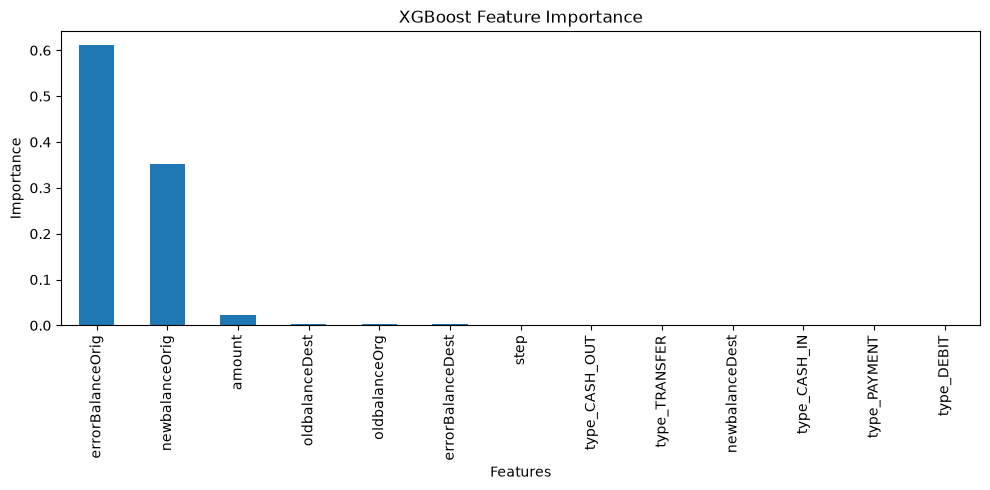

In [9]:
import matplotlib.pyplot as plt

importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

importance.plot(kind="bar", figsize=(10, 5))
plt.title("XGBoost Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

 XGBoost Feature Importance

Here we have looked at the importance of each feature within our XGBoost model. The feature importance graph can tell us which input variables are most important for our model.

From the results we can see that the most important feature is errorBalanceOrig, then newbalanceOrig and amount. All other features have a relatively low importance.

This allows us to see which transaction related features were most useful for predicting if a transaction was fraudulent.

In [10]:
import time
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

start = time.time()
xgb_reg = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)
xgb_reg.fit(X_train, y_train)
train_time = time.time() - start

pred = xgb_reg.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)
mae = mean_absolute_error(y_test, pred)

print("RMSE:", rmse)
print("R2:", r2)
print("MAE:", mae)
print("Training time (s):", train_time)

# Save so Person 3 can build the comparison table
pd.DataFrame([{"model": "XGBoost", "RMSE": rmse, "R2": r2,
               "MAE": mae, "train_time_s": train_time}]).to_csv("xgboost_results.csv", index=False)

RMSE: 0.002080407569706486
R2: 0.9966434836387634
MAE: 2.156534173991531e-05
Training time (s): 65.5001163482666


XGBoost regression model 

The code trains an XGBoost regression model with the provided training data. Then, it uses this trained model to make predictions on the testing data. To see how well the model performed, it calculated the Root Mean Squared Error (RMSE), R-squared (R²), and Mean Absolute Error (MAE). It also recorded how long the training took. All these results are saved in a file named xgboost_results.csv .